# Прогноз пит-стопа в Формуле-1

## 1. Постановка задачи

### 1.1. Бизнес-постановка

**Бизнес-задача:** заедет ли пилот на пит-лейн в течение следующих трёх кругов?

**Пользователь результата — гоночный стратег или аналитик команды.** По мере прохождения
гонки ему нужно оценивать вероятность скорой остановки соперников: это помогает
готовить ответную тактику и оценивать возможные изменения позиций после пит-стопов.

### 1.2. ML-постановка

**бинарная классификация с выдачей вероятности**

- Объект — **(гонка, пилот, завершённый круг t)**.
- Момент прогноза — конец круга t; текущий круг не должен быть кругом въезда или выезда из боксов.
- Данные — состав/возраст шин, номер круга, текущая позиция, история темпа и остановок, состояние трассы и последняя погода.

Используются реальные покруговые данные FastF1; источники и состав выгрузки описаны в разделе 3.

## 2. Метрики качества

**Основная метрика — PR-AUC: площадь под кривой Precision–Recall.** Заезды встречаются реже обычных кругов, а аналитику важны и доля верных предупреждений, и полнота обнаружения; PR-AUC учитывает оба показателя при разных порогах. Это подходит для сравнения моделей до выбора конкретного порога предупреждения.

**Дополнительные метрики:** Precision, Recall и F1 при пороге, подобранном на валидации 2023–2024.

Один пит-стоп создаёт несколько положительных окон. На следующем этапе нужна также
событийная оценка: доля заездов с хотя бы одним предварительным предупреждением
и число ложных предупреждений за гонку после объединения повторов. Построчный Recall
не равен доле обнаруженных уникальных пит-стопов.


## 3. Данные и воспроизводимость

Источник — исторический хронометраж F1, обработанный FastF1.
**Включены все 173 основные гонки из календарей 2018–2025 годов.** 
- Спринты, квалификации и тестовые сессии не включены. 
- Название Гран-при не всегда однозначно определяет трассу или её конфигурацию.

| Выборка | Сезоны | Назначение |
|---|---|---|
| Обучение | 2018–2022 | Обучение моделей и параметров предобработки |
| Валидация | 2023–2024 | Сравнение моделей, периода обучения и выбор порога |
| Тест | 2025 | Финальная проверка |

**Почему с 2018:** только с этого года доступны подробные данные FastF1.

Источник: [FastF1](https://github.com/theOehrly/Fast-F1)

In [ ]:
from pathlib import Path
import hashlib
import json
import platform
import importlib.metadata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.metrics import auc, precision_recall_curve

ROOT = Path.cwd()
FIGURES = ROOT / 'figures'
FIGURES.mkdir(exist_ok=True)
pd.set_option('display.max_columns', 14)
pd.set_option('display.max_rows', 25)
pd.set_option('display.precision', 3)
sns.set_theme(style='whitegrid', context='notebook', font='DejaVu Sans')
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titleweight': 'bold'})
COLORS = {0: '#426B8F', 1: '#D34A45'}
TYRE_COLORS = {'SOFT': '#E55353', 'MEDIUM': '#D5AD24', 'HARD': '#A5ADB7',
               'INTERMEDIATE': '#32A56B', 'WET': '#4B83C4', 'UNKNOWN': '#7B6D8D'}

def show_figure(fig, name):
    fig.savefig(FIGURES / f'{name}.png', bbox_inches='tight', facecolor='white')
    plt.show()
    plt.close(fig)

TRAIN_YEARS = list(range(2018, 2023))
VALID_YEARS = [2023, 2024]
TEST_YEARS = [2025]
np.random.seed(42)

python(47000) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(47002) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(47003) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Matplotlib is building the font cache; this may take a moment.


In [2]:
manifest = json.loads((ROOT / 'data/manifest.json').read_text())
data_file = ROOT / 'data' / manifest['combined_file']
raw = pd.read_csv(data_file, dtype={'RaceId': 'string', 'DriverNumber': 'string',
                                  'TrackStatus': 'string', 'Compound': 'string',
                                  'FastF1Generated': 'boolean', 'IsAccurate': 'boolean',
                                  'FreshTyre': 'boolean', 'Rainfall': 'boolean',
                                  'Deleted': 'boolean', 'IsPersonalBest': 'boolean'},
                  parse_dates=['RaceDate'], low_memory=False)

expected_ids = set()
for calendar in manifest['calendars']:
    path = ROOT / calendar['file']
    assert hashlib.sha256(path.read_bytes()).hexdigest() == calendar['sha256']
    for event in json.loads(path.read_text()):
        expected_ids.add(f"{calendar['year']}_{int(event['RoundNumber']):02d}")

sessions = pd.DataFrame(manifest['sessions'])
display(pd.Series({
    'Строк (пилот × круг)': len(raw), 'Столбцов': raw.shape[1],
    'Гонок': raw['RaceId'].nunique(), 'Уникальных пилотов': raw['Driver'].nunique(),
    'Названий команд': raw['Team'].nunique(),
    'Въездов на пит-лейн в исходных данных': raw['PitInTimeSeconds'].notna().sum(),
    'Первая гонка': str(raw['RaceDate'].min().date()),
    'Последняя гонка': str(raw['RaceDate'].max().date()),
}, name='Значение').to_frame())

display(raw[['RaceId', 'Driver', 'LapNumber', 'Compound', 'TyreLife',
             'LapTimeSeconds', 'Position', 'PitInTimeSeconds']].head(8))

,Значение
Строк (пилот × круг),189504
Столбцов,48
Гонок,173
Уникальных пилотов,43
Названий команд,19
Въездов на пит-лейн в исходных данных,6177
Первая гонка,2018-03-25
Последняя гонка,2025-12-07


,RaceId,Driver,LapNumber,Compound,TyreLife,LapTimeSeconds,Position,PitInTimeSeconds
0,2018_01,GAS,1,<NA>,NaN,105.060,17.0,NaN
1,2018_01,GAS,2,ULTRASOFT,1.0,93.372,17.0,NaN
2,2018_01,GAS,3,ULTRASOFT,2.0,92.861,17.0,NaN
3,2018_01,GAS,4,ULTRASOFT,3.0,92.184,17.0,NaN
4,2018_01,GAS,5,ULTRASOFT,4.0,92.332,17.0,NaN
5,2018_01,GAS,6,ULTRASOFT,5.0,98.180,16.0,NaN
6,2018_01,GAS,7,ULTRASOFT,6.0,91.537,16.0,NaN
7,2018_01,GAS,8,ULTRASOFT,7.0,91.319,16.0,NaN


`SOFT/MEDIUM/HARD` с 2019 года — обозначения относительно конкретного уик-энда: они не гарантируют
одинаковую физическую смесь на разных Гран-при. `TyreLife` может включать использование
комплекта до текущего отрезка. Смена `Stint` сама по себе не является меткой пит-стопа.
`IsAccurate=False` не означает автоматически неверное время круга: флаг учитывает также
пит-круги и нейтрализации. Поэтому фильтровать по нему весь датасет нельзя.

В 2018 использовались другие названия составов, включая SUPERSOFT, ULTRASOFT и HYPERSOFT.
В 2019 введены относительные HARD/MEDIUM/SOFT, а в 2022 — 18-дюймовые шины.
Поэтому в признаках сохраняется `TyreEra`, а `CompoundContext` объединяет период и название состава.
Старые названия не заменяются современными без сведений о выбранных смесях.

## 4. Первичная проверка данных

Проверяем все восемь сезонов: соответствие календарю, ключи, схему и пропуски.
Содержательные графики и выбор моделей далее используют только 2018–2024.

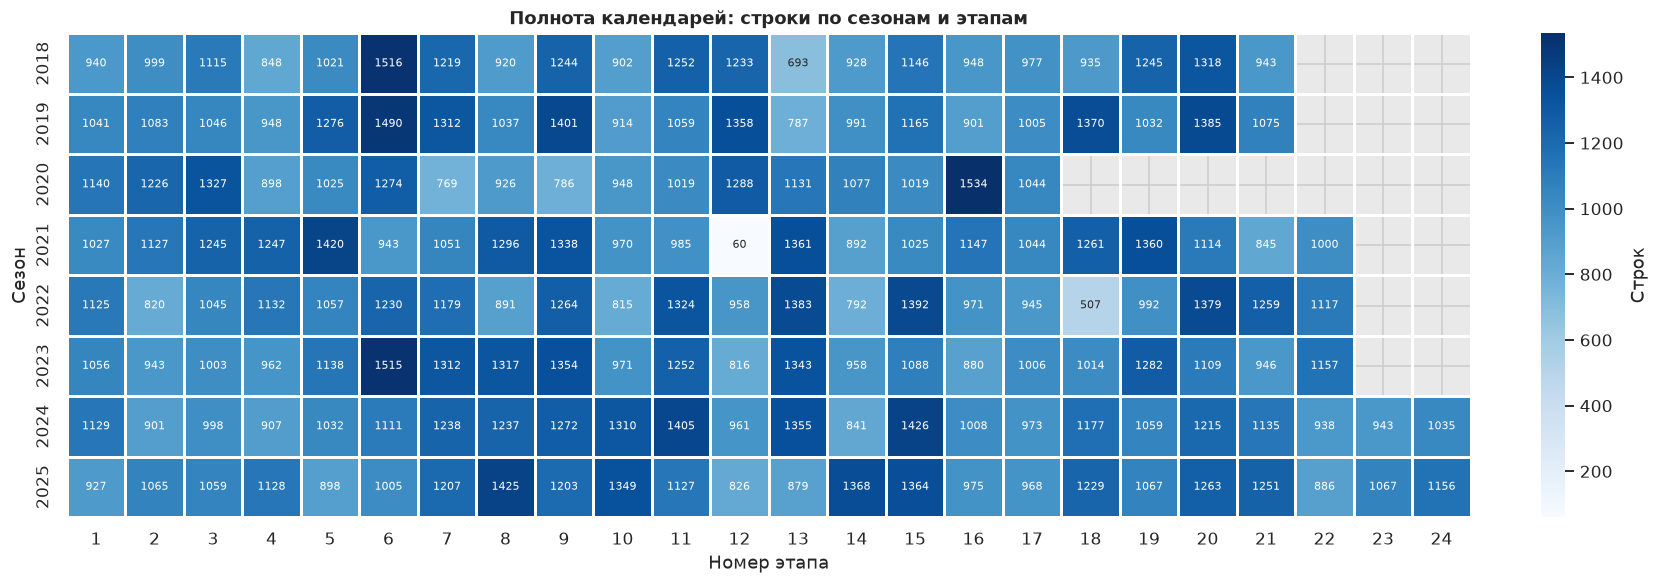

,Гонок,Строк,Пилотов,В_календаре
Year,,,,
2018,21,22342,20,21
2019,21,23676,20,21
2020,17,18431,23,17
2021,22,23758,21,22
2022,22,23577,22,22
2023,22,24422,22,22
2024,24,26606,24,24
2025,24,26692,21,24


In [ ]:
coverage = raw.groupby(['Year', 'RoundNumber'], observed=True).size().unstack()
fig, ax = plt.subplots(figsize=(15, 5.2), layout='constrained')
sns.heatmap(coverage, annot=True, fmt='.0f', annot_kws={'fontsize': 7}, cmap='Blues', linewidths=.7,
            cbar_kws={'label': 'Строк'}, ax=ax)
ax.set(title='Полнота календарей: строки по сезонам и этапам', xlabel='Номер этапа', ylabel='Сезон', facecolor='#E9E9E9')
ax.tick_params(axis='x', rotation=0)
show_figure(fig, '01_coverage')
coverage_year = raw.groupby('Year').agg(Гонок=('RaceId', 'nunique'), Строк=('RaceId', 'size'), Пилотов=('Driver', 'nunique'))
coverage_year['В_календаре'] = [sum(r.startswith(f'{y}_') for r in expected_ids) for y in coverage_year.index]
coverage_year


Выгрузка содержит все гонки календарей. Серые клетки — отсутствующие номера этапов в календаре этого года. Число кругов зависит от дистанции, сходов и остановок гонки. Особенно короткие гонки могут не дать ни одного полного трёхкругового горизонта. Соседние строки одной гонки зависимы, поэтому число строк не равно числу независимых ситуаций 

,Количество
Полные дубликаты строк,0
Повторные ключи гонка–пилот–круг,0
Строки без части ключа,0
Строки FastF1Generated,378
Круги без LapTimeSeconds,342
Круги с LapTimeSeconds ≤ 0,0
Строки без Compound,1333
Строки без TyreLife,1589
Отрицательный возраст шин,0
Дробные номера кругов,0


,Тип,Пропусков,Уникальных
LapNumber,int64,0,87
LapTimeSeconds,float64,342,55460
Compound,string,1333,9
TyreLife,float64,1589,78
Stint,float64,874,8
Position,float64,271,20
TrackStatus,string,1425,51
TrackTemp,float64,1126,434
AirTemp,float64,1126,263
Rainfall,boolean,1126,2


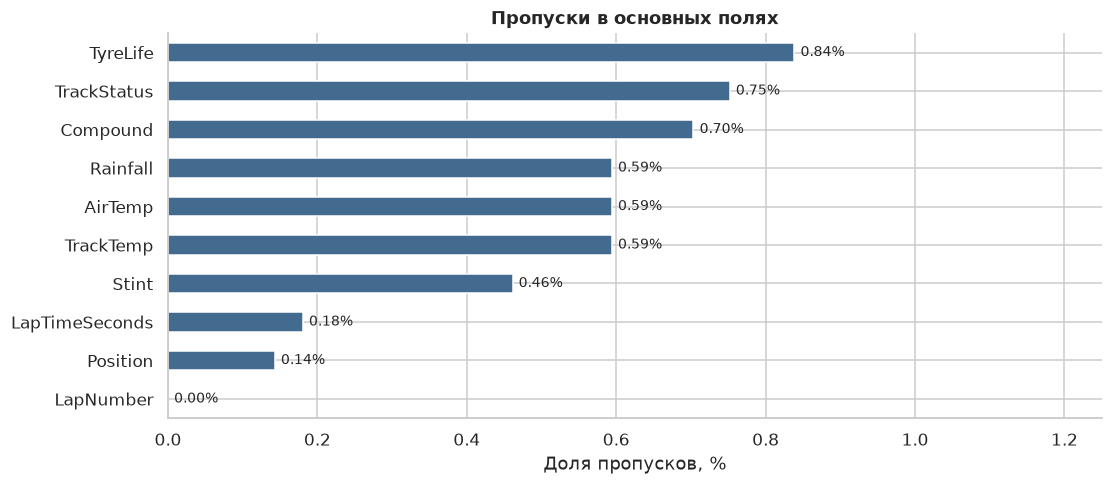

In [5]:
KEY = ['RaceId', 'DriverNumber', 'LapNumber']
audit = pd.Series({
    'Полные дубликаты строк': int(raw.duplicated().sum()),
    'Повторные ключи гонка–пилот–круг': int(raw.duplicated(KEY).sum()),
    'Строки без части ключа': int(raw[KEY].isna().any(axis=1).sum()),
    'Строки FastF1Generated': int(raw['FastF1Generated'].fillna(True).sum()),
    'Круги без LapTimeSeconds': int(raw['LapTimeSeconds'].isna().sum()),
    'Круги с LapTimeSeconds ≤ 0': int(raw['LapTimeSeconds'].le(0).sum()),
    'Строки без Compound': int(raw['Compound'].isna().sum()),
    'Строки без TyreLife': int(raw['TyreLife'].isna().sum()),
    'Отрицательный возраст шин': int(raw['TyreLife'].lt(0).sum()),
    'Дробные номера кругов': int((raw['LapNumber'].dropna() % 1 != 0).sum()),
    'Круги с IsAccurate=False/NA': int((~raw['IsAccurate'].fillna(False)).sum()),
}, name='Количество')
display(audit.to_frame())
important = ['LapNumber', 'LapTimeSeconds', 'Compound', 'TyreLife', 'Stint',
             'Position', 'TrackStatus', 'TrackTemp', 'AirTemp', 'Rainfall',
             'PitInTimeSeconds', 'PitOutTimeSeconds']
display(pd.DataFrame({'Тип': raw[important].dtypes.astype(str),
                      'Пропусков': raw[important].isna().sum(),
                      'Уникальных': raw[important].nunique()}))

feature_missing = raw[[c for c in important if not c.startswith('Pit')]].isna().mean().mul(100)
fig, ax = plt.subplots(figsize=(10, 4.3), layout='constrained')
feature_missing.sort_values().plot.barh(ax=ax, color='#426B8F')
ax.set(title='Пропуски в основных полях', xlabel='Доля пропусков, %', ylabel='')
for bar in ax.patches:
    ax.annotate(f'{bar.get_width():.2f}%', (bar.get_width(), bar.get_y() + bar.get_height()/2),
                xytext=(4, 0), textcoords='offset points', va='center', fontsize=9)
ax.set_xlim(0, max(1, feature_missing.max()) * 1.25)
show_figure(fig, '02_missing_values')

Пустые PitInTimeSeconds/PitOutTimeSeconds обычно означают отсутствие события, а не испорченное наблюдение: заполнять их средним или удалять такие строки нельзя. Пропуски времени круга и позиции имеют другой смысл и требуют отдельной обработки. Ключевые дубликаты проверены явно; одинаковые значения признаков у разных кругов не являются дубликатами.

## 5. Разметка и подготовка признаков

**Сначала размечаем будущие события на полной временной последовательности, затем
отбираем объекты для прогноза.** Если удалить пит-круги до разметки, положительные события исчезнут.
Будущие круги ищем по их номеру: следующие три строки после удаления пропусков не обязательно
соответствуют кругам t+1, t+2, t+3.

Искусственно добавленные FastF1 строки не считаем наблюдаемыми. Для завершённого круга
требуем время его окончания; отсутствие `LapTimeSeconds` при этом допускается как пропуск признака.
На этом этапе не удаляем SC/VSC, дождь и редкие составы шин: это важные режимы гонки.

**Метка события:** заполнено `PitInTimeSeconds`. Это зарегистрированный въезд на пит-лейн;
он не обязательно означает замену шин (возможны штраф, сход или красный флаг).
При неполных трёх будущих кругах цель неизвестна: строка исключается, даже если один заезд уже виден.
Это ограничивает применимость оценки около финишей и сходов.

In [6]:
laps = raw.sort_values(KEY).reset_index(drop=True).copy()
laps['LapNumber'] = laps['LapNumber'].astype(int)
laps['TyreEra'] = np.select([laps.Year.eq(2018), laps.Year.between(2019, 2021)],
                             ['2018', '2019–2021'], default='2022+')
laps['CompoundContext'] = laps['TyreEra'] + ':' + laps['Compound'].fillna('UNKNOWN')
laps['PitEntry'] = laps['PitInTimeSeconds'].notna()
laps['PitExit'] = laps['PitOutTimeSeconds'].notna()
laps['ObservedLap'] = (~laps['FastF1Generated'].fillna(True)
                       & laps['TimeSeconds'].notna())
lookup = laps.set_index(KEY)
future_seen = []
future_pits = []
for k in (1, 2, 3):
    future_keys = pd.MultiIndex.from_arrays([
        laps['RaceId'], laps['DriverNumber'], laps['LapNumber'] + k
    ], names=KEY)
    future_seen.append(lookup['ObservedLap'].reindex(future_keys).astype('boolean').fillna(False).to_numpy(dtype=bool))
    future_pits.append(lookup['PitEntry'].reindex(future_keys).astype('boolean').fillna(False).to_numpy(dtype=bool))

laps['FullHorizon'] = np.logical_and.reduce(future_seen)
laps['PitNext3'] = pd.array(np.logical_or.reduce(future_pits).astype(int), dtype='Int64')
laps.loc[~laps['FullHorizon'], 'PitNext3'] = pd.NA
laps['PitEntriesSoFar'] = laps.groupby(['RaceId', 'DriverNumber'], sort=False)['PitEntry'].cumsum()
laps['NeutralisedLap'] = laps['TrackStatus'].fillna('').str.contains('[467]')
laps['RedFlagLap'] = laps['TrackStatus'].fillna('').str.contains('5')
laps['TrackMode'] = np.select(
    [laps['RedFlagLap'].to_numpy(dtype=bool), laps['NeutralisedLap'].to_numpy(dtype=bool),
     laps['TrackStatus'].eq('1').fillna(False).to_numpy(dtype=bool)],
    ['Красный флаг', 'SC / VSC', 'Зелёный'], default='Жёлтый / смешанный / нет данных')

# История темпа — только уже завершённые чистые круги того же отрезка.
clean_pace = (laps['ObservedLap'] & ~laps['PitEntry'] & ~laps['PitExit']
              & laps['IsAccurate'].fillna(False) & laps['TrackStatus'].eq('1').fillna(False)
              & laps['LapTimeSeconds'].gt(0))
laps['CleanLapSeconds'] = laps['LapTimeSeconds'].where(clean_pace)
stint_groups = ['RaceId', 'DriverNumber', 'Stint']
pace_group = laps.groupby(stint_groups, sort=False, dropna=False)['CleanLapSeconds']
laps['RecentPaceSeconds'] = pace_group.transform(lambda s: s.rolling(3, min_periods=3).median())
three_lap_span = laps.groupby(stint_groups, sort=False, dropna=False)['LapNumber'].diff(2).eq(2)
laps.loc[~three_lap_span, 'RecentPaceSeconds'] = np.nan
previous_pace = pace_group.transform(lambda s: s.shift(3).rolling(3, min_periods=3).median())
laps['PaceChangePct'] = 100 * (laps['RecentPaceSeconds'] / previous_pace - 1)

# Проверка, что шесть использованных кругов действительно последовательны.
six_lap_span = laps.groupby(stint_groups, sort=False, dropna=False)['LapNumber'].diff(5).eq(5)
laps.loc[~six_lap_span, 'PaceChangePct'] = np.nan

mask = pd.Series(True, index=laps.index)
steps = [('Исходные строки', mask.copy())]
for name, condition in [
    ('Реальные завершённые круги', laps['ObservedLap']),
    ('Полностью наблюдаемые следующие 3 круга', laps['FullHorizon']),
    ('Текущий круг не въезд и не выезд', ~laps['PitEntry'] & ~laps['PitExit']),
]:
    mask &= condition
    steps.append((name, mask.copy()))
flow = pd.DataFrame([{'Этап': name, 'Осталось строк': int(m.sum())} for name, m in steps])
flow['Исключено на шаге'] = flow['Осталось строк'].shift(1).sub(flow['Осталось строк']).fillna(0).astype(int)
display(flow)
model_data = laps.loc[mask].copy()
model_data['PitNext3'] = model_data['PitNext3'].astype(int)
assert len(model_data) > 0
assert not model_data[['PitEntry', 'PitExit']].any().any()
assert model_data['FullHorizon'].all()
assert model_data['PitNext3'].isin([0, 1]).all()

# Группы разделены целыми гонками в хронологическом порядке.
train = model_data.loc[model_data['Year'].isin(TRAIN_YEARS)].copy()
valid = model_data.loc[model_data['Year'].isin(VALID_YEARS)].copy()
test = model_data.loc[model_data['Year'].isin(TEST_YEARS)].copy()
eda = pd.concat([train, valid]).copy()
eda_raw = laps.loc[laps['Year'].isin(TRAIN_YEARS + VALID_YEARS)].copy()
assert set(train.RaceId).isdisjoint(valid.RaceId)
assert set(pd.concat([train, valid]).RaceId).isdisjoint(test.RaceId)
assert train.RaceDate.max() < valid.RaceDate.min() < test.RaceDate.min()
display(pd.DataFrame([
    {'Часть': name, 'Сезоны': f'{part.Year.min()}–{part.Year.max()}', 'Строк': len(part), 'Гонок': part.RaceId.nunique()}
    for name, part in [('Обучение', train), ('Валидация', valid), ('Отложенный тест', test)]
]))
prepared_counts = model_data.groupby('RaceId').size()
empty_races = sessions.loc[~sessions.race_id.isin(prepared_counts.index), ['year', 'event', 'rows']]
display(empty_races.rename(columns={'year': 'Год', 'event': 'Гонка без допустимых объектов', 'rows': 'Исходных строк'}))

,Этап,Осталось строк,Исключено на шаге
0,Исходные строки,189504,0
1,Реальные завершённые круги,189126,378
2,Полностью наблюдаемые следующие 3 круга,179059,10067
3,Текущий круг не въезд и не выезд,167706,11353


,Часть,Сезоны,Строк,Гонок
0,Обучение,2018–2022,98981,102
1,Валидация,2023–2024,44992,46
2,Отложенный тест,2025–2025,23733,24


,Год,Гонка без допустимых объектов,Исходных строк
70,2021,Belgian Grand Prix,60


In [8]:
# Контрольная проверка разметки другим способом: по множеству номеров пит-кругов.
pit_sets = {key: set(g.loc[g.PitEntry, 'LapNumber'])
            for key, g in laps.groupby(['RaceId', 'DriverNumber'], sort=False)}
observed_sets = {key: set(g.loc[g.ObservedLap, 'LapNumber'])
                 for key, g in laps.groupby(['RaceId', 'DriverNumber'], sort=False)}
for row in model_data.itertuples():
    future = {row.LapNumber + 1, row.LapNumber + 2, row.LapNumber + 3}
    key = (row.RaceId, row.DriverNumber)
    assert future <= observed_sets[key]
    assert row.PitNext3 == int(bool(future & pit_sets[key]))

# Наглядный фрагмент: несколько кругов перед первым подходящим заездом.
example = eda.loc[eda['PitNext3'].eq(1)].iloc[0]
example_window = laps.loc[
    laps.RaceId.eq(example.RaceId) & laps.DriverNumber.eq(example.DriverNumber)
    & laps.LapNumber.between(example.LapNumber - 1, example.LapNumber + 5),
    ['RaceId', 'Driver', 'LapNumber', 'PitEntry', 'PitExit', 'TyreLife', 'PitNext3', 'FullHorizon']
]
example_window

,RaceId,Driver,LapNumber,PitEntry,PitExit,TyreLife,PitNext3,FullHorizon
9,2018_01,GAS,10,False,False,9.0,0,True
10,2018_01,GAS,11,False,False,10.0,1,True
11,2018_01,GAS,12,False,False,11.0,<NA>,False
12,2018_01,GAS,13,False,False,12.0,<NA>,False
13,2018_01,GAS,14,True,False,13.0,<NA>,False


### Какие столбцы можно подавать модели

Будущее допустимо использовать **для создания y**, но не для создания X.
Не допускаются: время следующей остановки, итоговая длина отрезка, итоговая позиция,
будущий состав шин, факт полного горизонта и агрегаты по всей гонке.
Нельзя нормировать номер круга на фактически пройденную дистанцию из будущего.

Ниже задан явный список кандидатов X. `RaceId`, даты, номера пилотов и служебные поля
сохраняются отдельно для группировки и аудита. Признаки темпа используют только текущий
и предыдущие круги. Исторические исправления FastF1 могут появляться после сессии:
офлайн-наличие поля ещё не подтверждает его задержку в реальном сервисе.

In [10]:
FEATURES = ['EventName', 'Driver', 'Team', 'LapNumber', 'CompoundContext', 'TyreEra', 'TyreLife',
            'FreshTyre', 'Stint', 'Position', 'PitEntriesSoFar', 'NeutralisedLap',
            'RedFlagLap', 'TrackTemp', 'AirTemp', 'Rainfall',
            'RecentPaceSeconds', 'PaceChangePct']
FORBIDDEN = {'PitNext3', 'FullHorizon', 'PitEntry', 'PitExit', 'PitInTimeSeconds',
             'PitOutTimeSeconds', 'FastF1Generated', 'IsAccurate', 'ObservedLap'}

X_train, y_train = train[FEATURES].copy(), train['PitNext3'].copy()

print("PaceChangePct: ",eda.PaceChangePct.isna().mean())

eda[['LapNumber', 'TyreLife', 'Position', 'LapTimeSeconds', 'TrackTemp',
             'RecentPaceSeconds', 'PaceChangePct']].describe(
                 percentiles=[.01, .25, .5, .75, .99]).T

PaceChangePct:  0.42403784042841364


,count,mean,std,min,1%,25%,50%,75%,99%,max
LapNumber,143973.0,29.335,17.728,1.000,1.000,14.000,28.000,43.000,67.000,84.000
TyreLife,143156.0,14.934,10.170,1.000,1.000,7.000,13.000,21.000,46.000,75.000
Position,143973.0,9.629,5.363,1.000,1.000,5.000,10.000,14.000,20.000,20.000
LapTimeSeconds,143973.0,91.066,15.539,55.404,68.118,80.788,88.556,99.375,150.760,197.279
TrackTemp,143048.0,35.710,8.982,13.800,15.900,29.400,35.200,42.500,54.200,57.500
RecentPaceSeconds,107187.0,88.186,11.604,56.442,67.849,79.674,85.866,97.490,112.934,130.767
PaceChangePct,82923.0,-0.062,0.800,-22.300,-2.274,-0.340,-0.047,0.251,1.963,22.254


В X предложено 18 признаков. В EDA отсутствует PaceChangePct у 42.4% объектов: для него нужны шесть подряд идущих чистых кругов одного отрезка. Это структурный пропуск после старта, смены шин или нейтрализации; удаление всех таких строк изменило бы область применения модели.

## 6. Разведочный анализ (2018–2024)
### 6.1. Баланс классов и различия гонок

Проверим, насколько редок целевой класс и одинаков ли базовый риск в разных гонках.
Доли считаются **среди допустимых моментов прогноза**, а не среди всех исходных кругов.

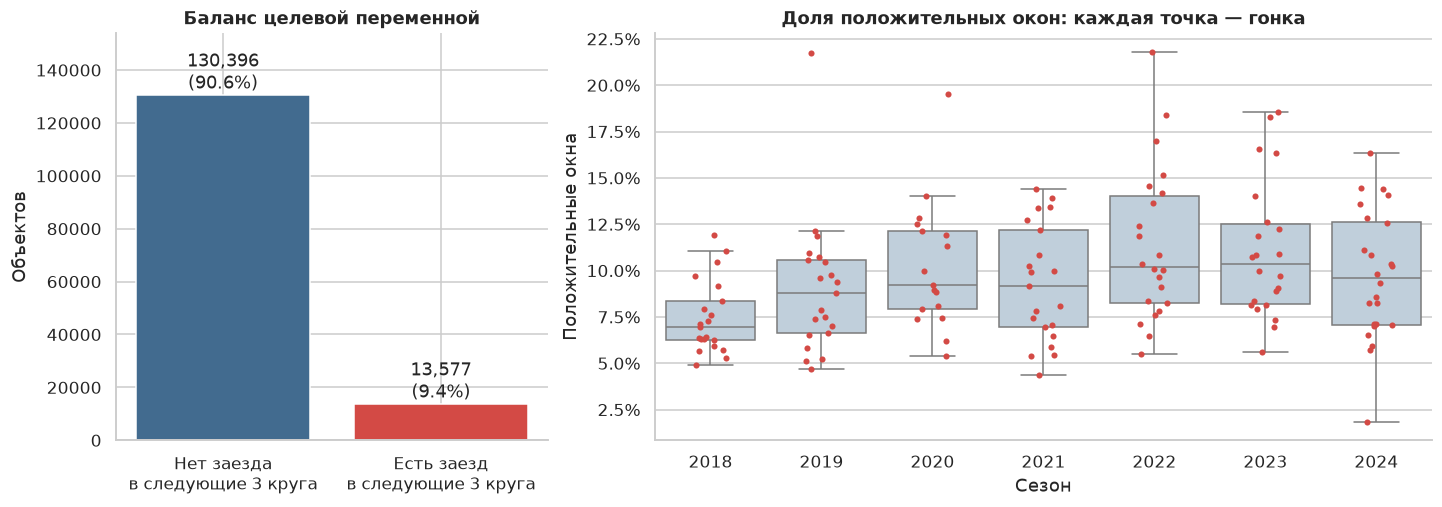

In [11]:
balance = eda['PitNext3'].value_counts().reindex([0, 1], fill_value=0)
race_rates = eda.groupby(['Year', 'RaceId'], observed=True)['PitNext3'].mean().reset_index(name='Rate')
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={'width_ratios': [1, 1.8]}, layout='constrained')
axes[0].bar(['Нет заезда\nв следующие 3 круга', 'Есть заезд\nв следующие 3 круга'], balance.values, color=[COLORS[0], COLORS[1]])
for i, n in enumerate(balance.values):
    axes[0].text(i, n + balance.max()*.02, f'{n:,}\n({n / balance.sum():.1%})', ha='center')
axes[0].set(title='Баланс целевой переменной', ylabel='Объектов', ylim=(0, balance.max()*1.18))
sns.boxplot(race_rates, x='Year', y='Rate', color='#BBD0DF', showfliers=False, ax=axes[1])
sns.stripplot(race_rates, x='Year', y='Rate', color='#D34A45', jitter=.15, size=4, ax=axes[1])
axes[1].set(title='Доля положительных окон: каждая точка — гонка', xlabel='Сезон', ylabel='Положительные окна')
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
show_figure(fig, '03_target_balance')
prevalence = eda['PitNext3'].mean()

Положительный класс составляет 9.4% (13,577 из 143,973). Правило «всегда 0» получило бы accuracy 90.6%, но Recall=0. Доля по гонкам меняется от 1.8% до 21.8%. Рядом с PR-AUC нужно публиковать долю класса и результаты по сезонам и гонкам. Объединённая оценка сильнее взвешивает длинные гонки.

### 6.2. Распределения и необычные значения

Рассмотрим возраст шин, позицию, температуру трассы и время круга.
Длинные круги могут быть следствием красных флагов или нейтрализации, поэтому
правило «удалить всё за пределами 1.5 IQR» без предметного анализа здесь нежелательно.

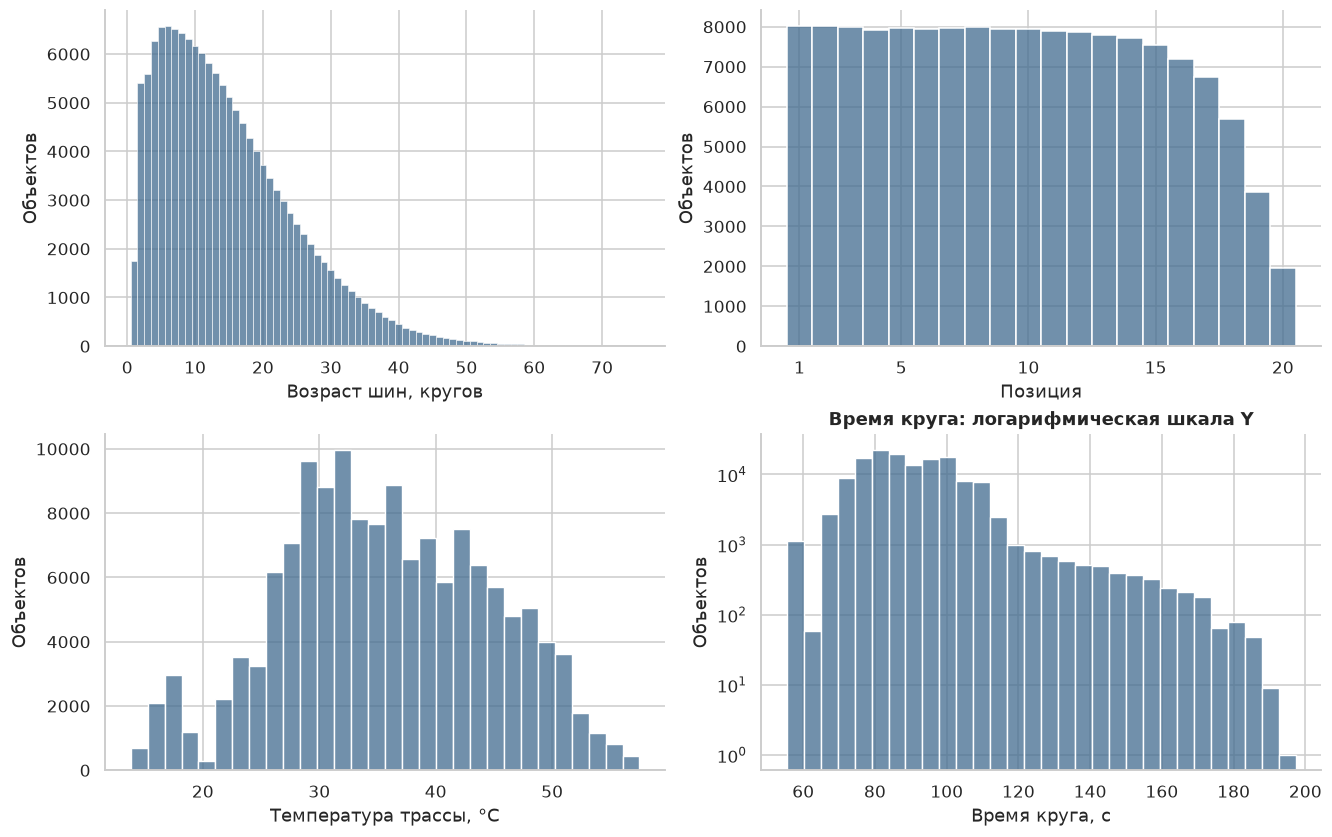

,Year,EventName,Driver,LapNumber,LapTimeSeconds,TrackStatus,IsAccurate
70885,2021,Azerbaijan Grand Prix,VER,32,197.279,4,False
3607,2018,Azerbaijan Grand Prix,VET,2,189.319,4,False
3474,2018,Azerbaijan Grand Prix,RIC,2,189.041,4,False
3515,2018,Azerbaijan Grand Prix,VER,2,188.783,4,False
3556,2018,Azerbaijan Grand Prix,HAM,2,188.609,4,False


Медианное время круга равно 88.6 с, 99-й перцентиль — 150.8 с, максимум — 197.3 с. 


In [12]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5), layout='constrained')
for ax, col, label in zip(axes.flat,
                         ['TyreLife', 'Position', 'TrackTemp', 'LapTimeSeconds'],
                         ['Возраст шин, кругов', 'Позиция', 'Температура трассы, °C', 'Время круга, с']):
    if col in ['TyreLife', 'Position']:
        sns.histplot(eda, x=col, discrete=True, color='#426B8F', ax=ax)
    else:
        sns.histplot(eda, x=col, bins=30, color='#426B8F', ax=ax)
    ax.set(xlabel=label, ylabel='Объектов')
    if col == 'LapTimeSeconds':
        ax.set_yscale('log')
        ax.set_title('Время круга: логарифмическая шкала Y')
    if col == 'Position':
        ax.set_xticks([1, 5, 10, 15, 20])
show_figure(fig, '04_distributions')
display(eda.nlargest(5, 'LapTimeSeconds')[
    ['Year', 'EventName', 'Driver', 'LapNumber', 'LapTimeSeconds', 'TrackStatus', 'IsAccurate']])
print(f'Медианное время круга равно {eda.LapTimeSeconds.median():.1f} с, '
    f'99-й перцентиль — {eda.LapTimeSeconds.quantile(.99):.1f} с, '
    f'максимум — {eda.LapTimeSeconds.max():.1f} с. ')

Трассы имеют разную длину, поэтому абсолютные времена нельзя напрямую трактовать как превосходство пилота. Для модели полезнее изменение собственного темпа внутри отрезка и контекст трассы; исходные экстремальные значения сохраняем для аудита.

### 6.3. Возраст шин и риск скорого заезда

Сравним долю положительных окон в пятикруговых интервалах возраста шин.
Для каждой точки используется свой знаменатель — количество доступных наблюдений в этой группе.
Группы с менее чем 60 объектами не рисуются, чтобы единичные случаи не выглядели закономерностью.
Соседние круги зависимы, поэтому обычные доверительные интервалы для независимых строк не строятся.

Для сопоставимости обозначений SOFT/MEDIUM/HARD этот график использует 2019–2024. Данные 2018 остаются в общей выборке и отдельно рассматриваются в сравнении сезонов.

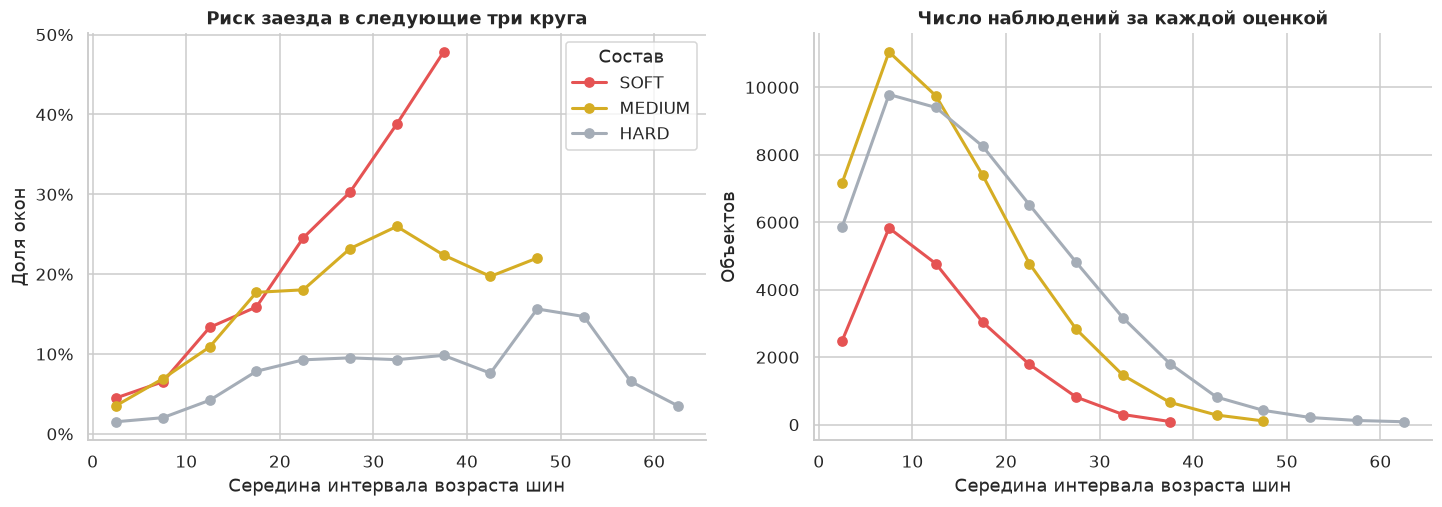

,Объектов,Доля_заезда,Медианный_возраст
Compound,,,
HARD,51552,0.060,15.0
HYPERSOFT,783,0.184,10.0
INTERMEDIATE,6667,0.125,12.0
MEDIUM,48348,0.117,12.0
SOFT,26098,0.112,12.0
SUPERSOFT,5466,0.063,16.0
ULTRASOFT,3829,0.096,13.0
WET,585,0.374,7.0


При возрасте 15–19 кругов доля положительных окон на SOFT — 15.9% (n=3039), на HARD — 7.8% (n=8255). 


In [14]:
eda['TyreAgeBin'] = (np.floor(eda['TyreLife'] / 5) * 5).astype('Int64')
age_rates = (eda.loc[eda.Year.ge(2019)].groupby(['Compound', 'TyreAgeBin'], observed=True)['PitNext3']
             .agg(n='size', rate='mean', positive='sum').reset_index())
age_plot = age_rates.loc[age_rates.n.ge(60) & age_rates.Compound.isin(['SOFT', 'MEDIUM', 'HARD'])]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), layout='constrained')
for compound in ['SOFT', 'MEDIUM', 'HARD']:
    part = age_plot.loc[age_plot.Compound.eq(compound)]
    axes[0].plot(part.TyreAgeBin.astype(float) + 2.5, part.rate, marker='o',
                 label=compound, color=TYRE_COLORS[compound], linewidth=2)
    axes[1].plot(part.TyreAgeBin.astype(float) + 2.5, part.n, marker='o',
                 label=compound, color=TYRE_COLORS[compound], linewidth=2)
axes[0].set(title='Риск заезда в следующие три круга', xlabel='Середина интервала возраста шин', ylabel='Доля окон')
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
axes[1].set(title='Число наблюдений за каждой оценкой', xlabel='Середина интервала возраста шин', ylabel='Объектов')
axes[0].legend(title='Состав')
show_figure(fig, '05_tyre_age_risk')
display(eda.groupby('Compound', observed=True).agg(
    Объектов=('PitNext3', 'size'), Доля_заезда=('PitNext3', 'mean'), Медианный_возраст=('TyreLife', 'median')))
age_compare = age_rates.loc[age_rates.TyreAgeBin.eq(15)].set_index('Compound')
print(f'При возрасте 15–19 кругов доля положительных окон на SOFT — '
           f'{age_compare.loc["SOFT", "rate"]:.1%} (n={int(age_compare.loc["SOFT", "n"])}), '
           f'на HARD — {age_compare.loc["HARD", "rate"]:.1%} '
           f'(n={int(age_compare.loc["HARD", "n"])}). ')

Возраст шин следует использовать вместе с составом и трассой. По правому графику видно, где оценка опирается на малую выборку. Кривые описывают наблюдаемые решения команд: отбор длинных отрезков, погода и положение в гонке не позволяют трактовать их как причинный эффект износа.

### 6.4. Когда команды заезжают в боксы на разных трассах

Теперь единица анализа — сам зарегистрированный въезд, а не окно прогноза.
В каждой панели считаются заезды за две гонки соответствующего Гран-при.
Номера кругов абсолютные; длина дистанции и количество остановок различаются.

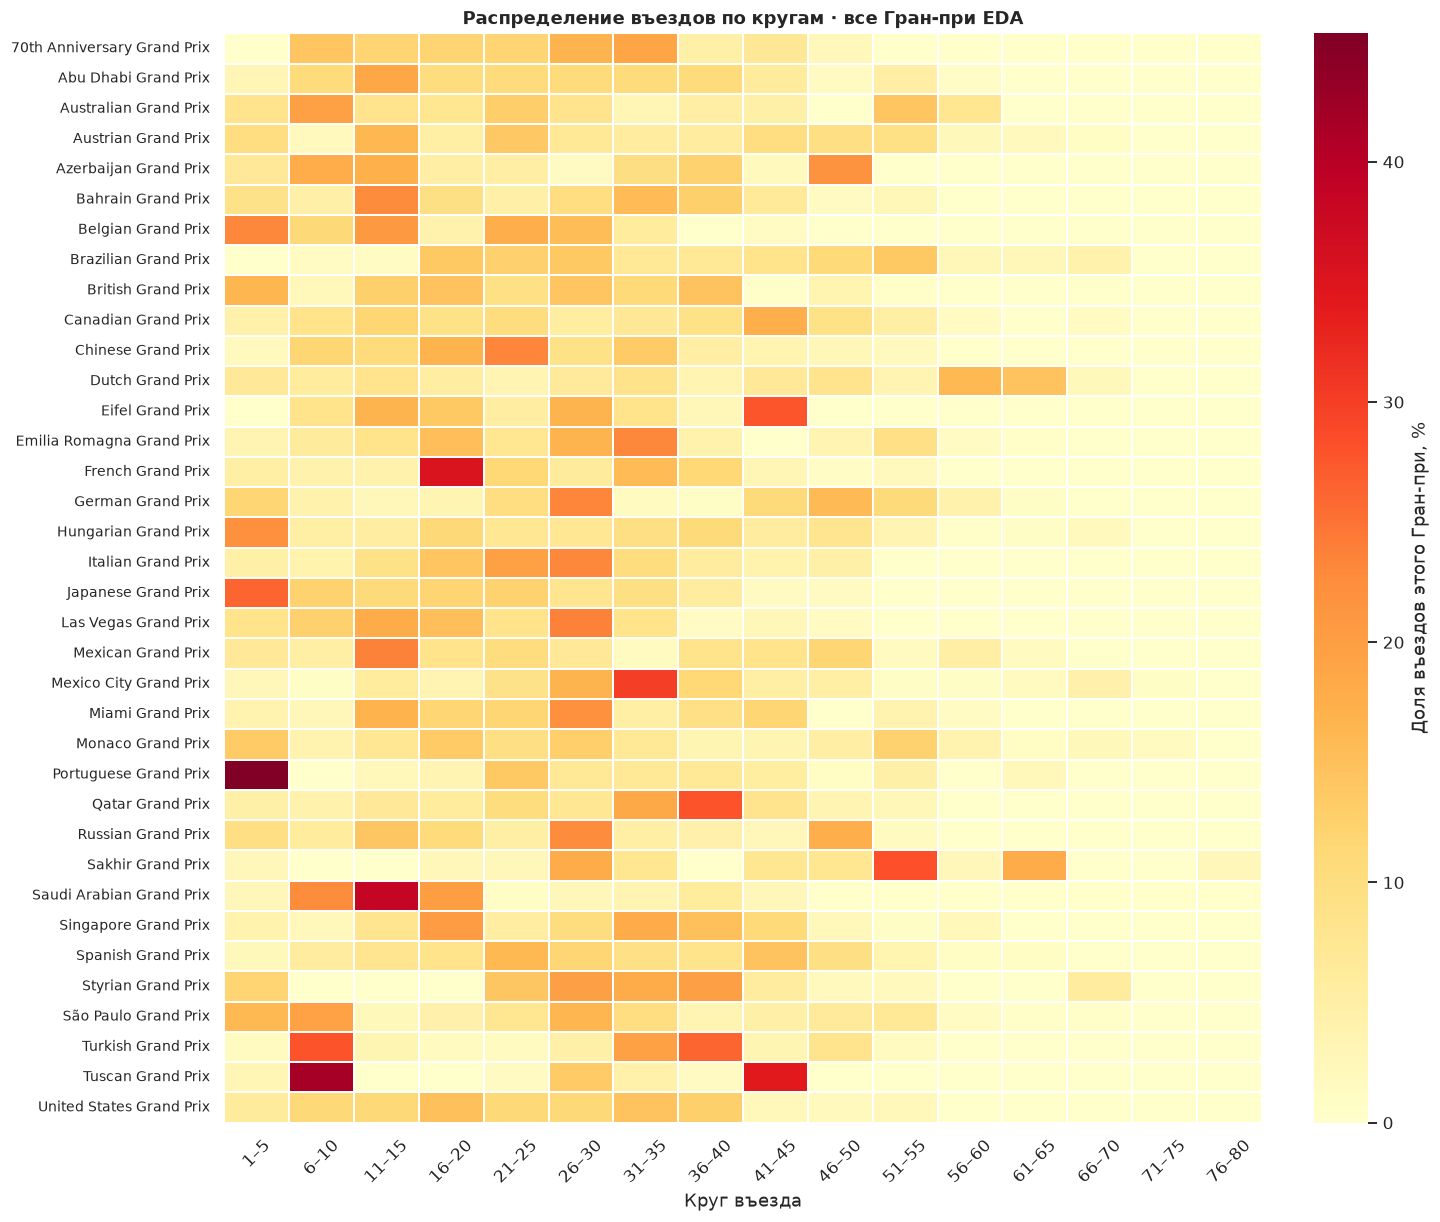

,count,mean,median,max
EventName,,,,
70th Anniversary Grand Prix,20,2.100,2.0,3
Abu Dhabi Grand Prix,139,1.468,1.0,4
Australian Grand Prix,99,1.707,1.0,6
Austrian Grand Prix,140,1.929,2.0,4
Azerbaijan Grand Prix,120,1.692,1.0,6
...,...,...,...,...
Styrian Grand Prix,40,1.250,1.0,3
São Paulo Grand Prix,79,2.924,3.0,5
Turkish Grand Prix,40,1.525,1.0,3


In [16]:
pit_events = eda_raw.loc[eda_raw.PitEntry & eda_raw.ObservedLap].copy()
upper = int(np.ceil(pit_events.LapNumber.max()/5)*5)
pit_events['LapBin'] = pd.cut(pit_events.LapNumber, bins=np.arange(0, upper+1, 5), include_lowest=True,
                              labels=[f'{n+1}–{n+5}' for n in range(0, upper, 5)])
windows = pd.crosstab(pit_events.EventName, pit_events.LapBin)
windows = windows.div(windows.sum(axis=1), axis=0)*100
windows = windows.sort_index()
fig, ax = plt.subplots(figsize=(13, 11), layout='constrained')
sns.heatmap(windows, cmap='YlOrRd', linewidths=.3, ax=ax, cbar_kws={'label': 'Доля въездов этого Гран-при, %'})
ax.set(title='Распределение въездов по кругам · все Гран-при EDA', xlabel='Круг въезда', ylabel='')
ax.tick_params(axis='y', labelsize=9, rotation=0)
ax.tick_params(axis='x', rotation=45)
show_figure(fig, '06_pit_windows')
stops_per_entry = (eda_raw.groupby(['RaceId', 'DriverNumber', 'EventName'], observed=True)['PitEntry'].sum().reset_index(name='PitEntries'))
display(stops_per_entry.groupby('EventName', observed=True).PitEntries.agg(['count', 'mean', 'median', 'max']))


На графике представлены все названия Гран-при из EDA, без отбора шести трасс. Каждая строка нормирована на своё число заездов, поэтому частые Гран-при не подавляют редкие. Пики не являются оптимальными окнами: здесь смешаны сезоны, длины гонок и внеплановые события. Одна трасса может встречаться под разными названиями; в дальнейшем нужен справочник конфигураций.

### 6.5. Длина отрезков и незавершённые наблюдения

Длину отрезка можно посчитать после его завершения и использовать в EDA,
но **нельзя подавать её модели как признак текущего круга**.
Не все отрезки заканчиваются въездом: гонка может завершиться, пилот может сойти,
а состав может смениться во время красного флага. Поэтому разделяем эти случаи.

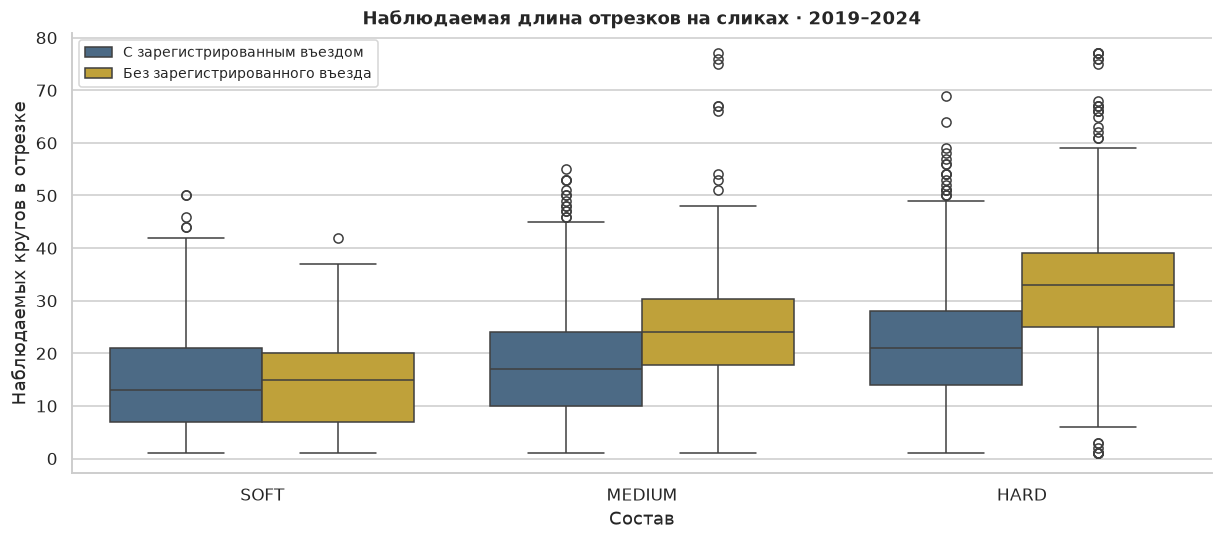

У 2676 из 7961 отрезков нет 


In [17]:
stints = (eda_raw.loc[eda_raw.ObservedLap & eda_raw.Stint.notna()]
          .groupby(['RaceId', 'DriverNumber', 'Stint'], observed=True)
          .agg(Year=('Year', 'first'), Compound=('Compound', 'first'), FirstLap=('LapNumber', 'min'),
               LastLap=('LapNumber', 'max'), ObservedLaps=('LapNumber', 'size'),
               EndedByPitEntry=('PitEntry', 'max'), MaxTyreAge=('TyreLife', 'max'))
          .reset_index())
stints['Status'] = np.where(stints.EndedByPitEntry, 'С зарегистрированным въездом', 'Без зарегистрированного въезда')
fig, ax = plt.subplots(figsize=(11, 4.8), layout='constrained')
sns.boxplot(stints.loc[stints.Year.ge(2019) & stints.Compound.isin(['SOFT', 'MEDIUM', 'HARD'])], x='Compound',
            y='ObservedLaps', hue='Status', order=['SOFT', 'MEDIUM', 'HARD'],
            palette=['#426B8F', '#D5AD24'], ax=ax)
ax.set(title='Наблюдаемая длина отрезков на сликах · 2019–2024', xlabel='Состав', ylabel='Наблюдаемых кругов в отрезке')
ax.legend(title='', loc='upper left', fontsize=9)
show_figure(fig, '07_stint_lengths')
print(f'У {int((~stints.EndedByPitEntry).sum())} из {len(stints)} отрезков нет ')

Такие отрезка нельзя считать завершившими полный ресурс шин. Если оценивать «срок службы» только по отрезкам с остановкой, возникает смещение отбора; для специальной модели длительности уместен анализ выживаемости с цензурированием.

### 6.6. Нейтрализации, температура и команды

Сначала сравним контекст **текущего** круга с событием в следующих трёх.
Статус означает, что режим встречался в течение круга; это не точное состояние
трассы на момент каждого решения. Здесь наблюдаемые связи, а не эксперимент.

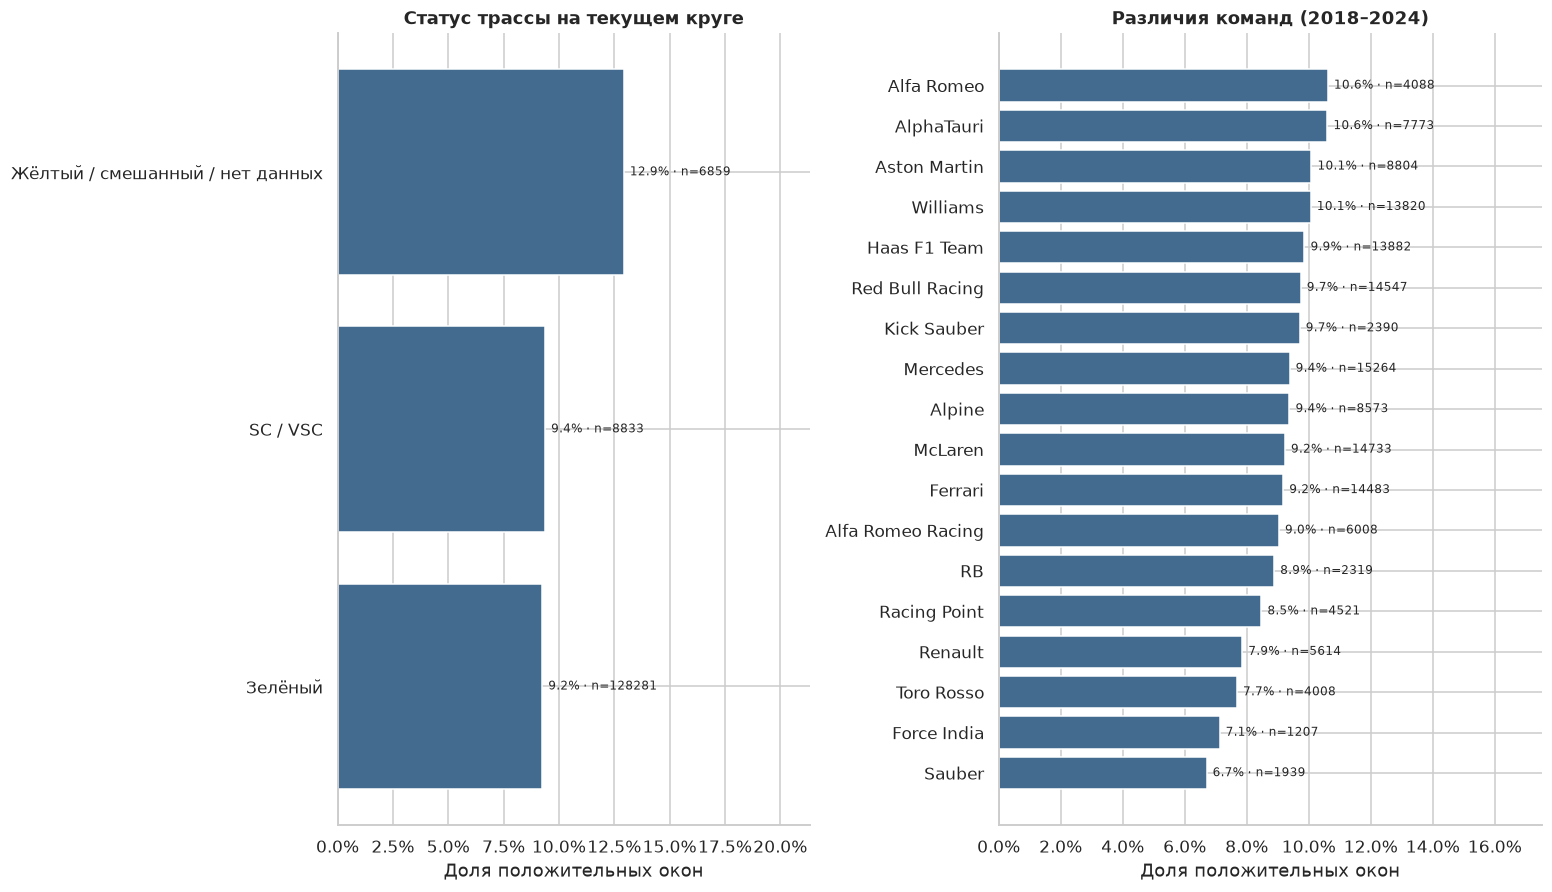

,n,rate
TrackMode,,
Зелёный,128281,0.092
SC / VSC,8833,0.094
Жёлтый / смешанный / нет данных,6859,0.129


В выбранных окнах доля будущих заездов при SC/VSC — 9.4%, при зелёном статусе — 9.2%. Эти условные доли не доказывают, что SC 


In [18]:
mode_rates = eda.groupby('TrackMode', observed=True).PitNext3.agg(n='size', rate='mean').sort_values('rate')
team_rates = eda.groupby('Team', observed=True).PitNext3.agg(n='size', rate='mean').sort_values('rate')
fig, axes = plt.subplots(1, 2, figsize=(14, 8), layout='constrained', gridspec_kw={'width_ratios': [1, 1.15]})
for ax, stats, title in [(axes[0], mode_rates, 'Статус трассы на текущем круге'),
                          (axes[1], team_rates, 'Различия команд (2018–2024)')]:
    bars = ax.barh(stats.index, stats.rate, color='#426B8F')
    for bar, (_, row) in zip(bars, stats.iterrows()):
        ax.annotate(f'{row.rate:.1%} · n={int(row.n)}',
                    (bar.get_width(), bar.get_y()+bar.get_height()/2),
                    xytext=(4, 0), textcoords='offset points', va='center', fontsize=8)
    ax.set(title=title, xlabel='Доля положительных окон', xlim=(0, stats.rate.max() * 1.65))
    ax.xaxis.set_major_formatter(PercentFormatter(1))
show_figure(fig, '08_track_status_teams')
display(mode_rates)
print(f'В выбранных окнах доля будущих заездов при SC/VSC — '
           f'{mode_rates.loc["SC / VSC", "rate"]:.1%}, при зелёном статусе — '
           f'{mode_rates.loc["Зелёный", "rate"]:.1%}. Эти условные доли не доказывают, что SC ')

Эти условные доли не доказывают, что SC сам по себе изменяет число остановок: текущие пит-круги исключены, а нейтрализация может продолжаться уже после массовых заездов. Горизонт и отбор объектов важны для интерпретации. Статусы трассы могут объяснять коллективные изменения стратегии, поэтому SC/VSC не следует удалять из задачи прогнозирования остановок. Редкие режимы показаны вместе с n. Различия команд также зависят от трассы, погоды, стартовой позиции и сходов: график не является рейтингом качества стратегов. Переименования команд между сезонами потребуют аккуратного кодирования категорий.

### 6.7. Изменение темпа перед остановкой

`PaceChangePct` сравнивает медиану последних трёх чистых кругов с медианой трёх
предшествующих, только внутри одного отрезка. Положительное значение означает замедление.
Ни будущий пит-круг, ни будущая длина отрезка в расчёте не участвуют.

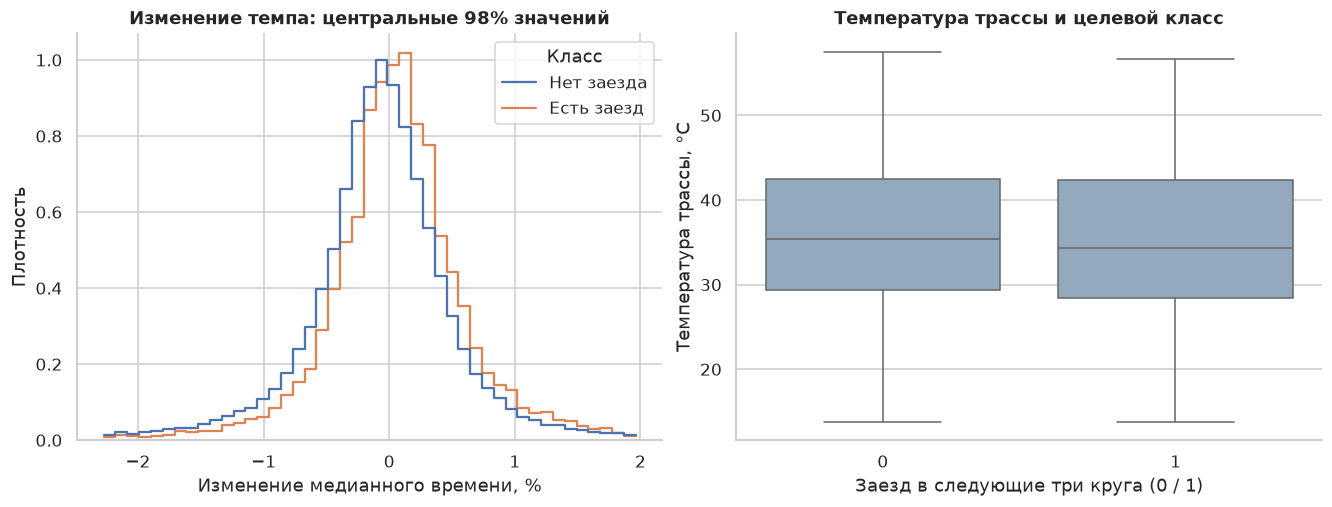

,count,median,mean
PitNext3,,,
0,73429,-0.060,-0.081
1,9494,0.063,0.083


In [19]:
pace_view = eda.loc[eda.PaceChangePct.notna()].copy()
lo, hi = pace_view.PaceChangePct.quantile([.01, .99])
pace_visible = pace_view.loc[pace_view.PaceChangePct.between(lo, hi)].copy()
pace_visible['Класс'] = pace_visible.PitNext3.map({0: 'Нет заезда', 1: 'Есть заезд'})
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout='constrained')
sns.histplot(pace_visible, x='PaceChangePct', hue='Класс', bins=45,
             stat='density', common_norm=False, element='step', fill=False, ax=axes[0])
axes[0].set(title='Изменение темпа: центральные 98% значений', xlabel='Изменение медианного времени, %', ylabel='Плотность')
sns.boxplot(eda, x='PitNext3', y='TrackTemp', color='#8CABC5', ax=axes[1])
axes[1].set(title='Температура трассы и целевой класс', xlabel='Заезд в следующие три круга (0 / 1)', ylabel='Температура трассы, °C')
show_figure(fig, '09_pace_weather')
display(pace_view.groupby('PitNext3').PaceChangePct.agg(['count', 'median', 'mean']))

### 6.8. Корреляции числовых признаков

Используем коэффициент Спирмена, чтобы рассмотреть монотонные связи и дублирование
числовой информации. Категориям не присваиваются произвольные числовые коды.
Парные корреляции рассчитаны по доступным парам; они не измеряют качество будущей модели.

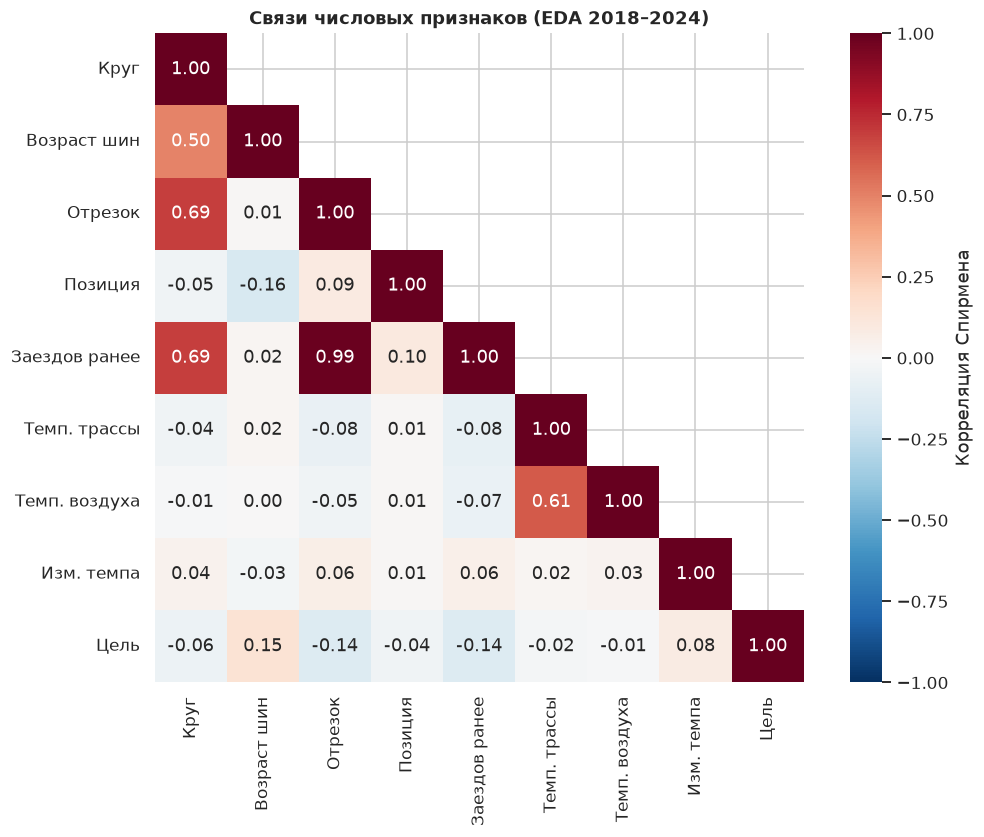

In [20]:
corr_columns = ['LapNumber', 'TyreLife', 'Stint', 'Position', 'PitEntriesSoFar',
                'TrackTemp', 'AirTemp', 'PaceChangePct', 'PitNext3']
corr_names = ['Круг', 'Возраст шин', 'Отрезок', 'Позиция', 'Заездов ранее',
              'Темп. трассы', 'Темп. воздуха', 'Изм. темпа', 'Цель']
corr = eda[corr_columns].corr(method='spearman')
corr.index = corr_names
corr.columns = corr_names
fig, ax = plt.subplots(figsize=(10, 7.5), layout='constrained')
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool), k=1), annot=True, fmt='.2f',
            cmap='RdBu_r', vmin=-1, vmax=1, center=0, square=True, ax=ax,
            cbar_kws={'label': 'Корреляция Спирмена'})
ax.set_title('Связи числовых признаков (EDA 2018–2024)')
show_figure(fig, '10_correlations')

Корреляция номера отрезка и числа прошлых заездов — 0.99, температуры воздуха и трассы — 0.61. Номер отрезка и число прошлых заездов содержат близкую информацию; при дальнейшем моделировании стоит сравнить наборы признаков и проверить устойчивость. Низкая парная корреляция с бинарной целью не исключает полезность нелинейного взаимодействия возраста шин, трассы и состава.

### 6.9. Визуальный разбор одной гонки: Венгрия, 2023

Проверим предметный смысл данных на конкретной гонке: цвет показывает состав шин,
разрыв/граница — смену отрезка, чёрный маркер — зарегистрированный въезд.
Пилоты расположены по алфавиту; порядок не является финишной классификацией.
Это ретроспективная визуализация, не набор признаков модели.

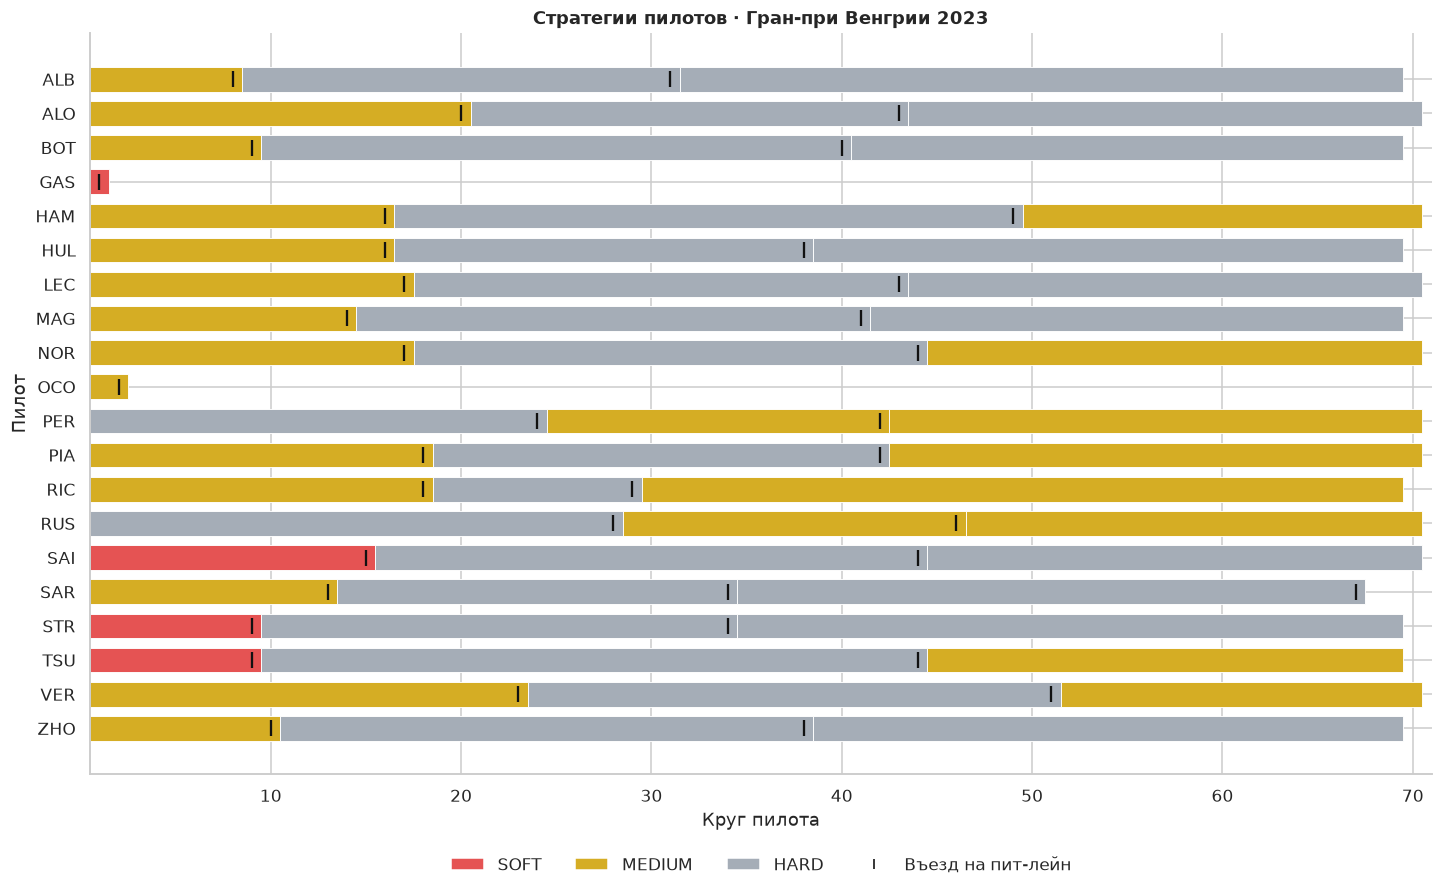

In [21]:
race = eda_raw.loc[eda_raw.Year.eq(2023) & eda_raw.EventName.eq('Hungarian Grand Prix')].copy()
assert not race.empty
drivers = sorted(race.Driver.dropna().unique())
fig, ax = plt.subplots(figsize=(13, 8), layout='constrained')
for y, driver in enumerate(drivers):
    driver_laps = race.loc[race.Driver.eq(driver)].sort_values('LapNumber')
    for (_, compound), group in driver_laps.groupby(['Stint', 'Compound'], observed=True):
        start, end = group.LapNumber.min(), group.LapNumber.max()
        ax.barh(y, end-start+1, left=start-.5, height=.72,
                color=TYRE_COLORS.get(compound, '#7B6D8D'), edgecolor='white', linewidth=.6)
    entries = driver_laps.loc[driver_laps.PitEntry, 'LapNumber']
    ax.scatter(entries, [y]*len(entries), marker='|', color='#111111', s=110, linewidths=1.5, zorder=3)
ax.set_yticks(range(len(drivers)), drivers)
ax.invert_yaxis()
ax.set(title='Стратегии пилотов · Гран-при Венгрии 2023', xlabel='Круг пилота', ylabel='Пилот', xlim=(.5, race.LapNumber.max()+1))
present = [c for c in TYRE_COLORS if c in race.Compound.unique()]
handles = [Patch(facecolor=TYRE_COLORS[c], label=c) for c in present]
handles.append(plt.Line2D([0], [0], marker='|', color='black', linestyle='', label='Въезд на пит-лейн'))
ax.legend(handles=handles, loc='upper center', bbox_to_anchor=(.5, -.09), ncol=len(handles), frameon=False)
show_figure(fig, '11_race_strategies')

В выбранной гонке отображены 20 пилотов и 39 зарегистрированных въездов. Укороченная полоса означает сход, а не завершение ресурса шин. Синхронные остановки и разные длины отрезков показывают, зачем модели нужны история пилота и общий контекст гонки.